<a href="https://colab.research.google.com/github/Hossain-Mahmud00/cantera-projects/blob/main/Cantera_methane_combustion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install cantera

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.3/19.3 MB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 5.2 MB/s eta 0:00:00


In [2]:

import cantera as ct
gas = ct.Solution('gri30.yaml')
print(gas.n_species)

53


In [3]:

gas.TPX = 300, ct.one_atm, 'CH4:1, O2:2, N2:7.52'
print(gas.T)
print(gas.P)
print(gas.density)

300.0
101325.00000000001
1.122527162471166


In [4]:

gas.equilibrate('HP')
print(gas.T)

2225.524583476995


In [5]:

for name in ['CH4', 'O2', 'CO2', 'H2O', 'CO', 'N2']:
    print(name, gas[name].X)

CH4 [3.03297231e-17]
O2 [0.00462224]
CO2 [0.08536422]
H2O [0.18346659]
CO [0.00898794]
N2 [0.70858382]


In [6]:

print(gas.X.sum())
for name in ['OH', 'NO', 'H2', 'H', 'O']:
    print(name, gas[name].X)

1.0
OH [0.00287541]
NO [0.00188821]
H2 [0.00360453]
H [0.00039035]
O [0.00021566]


In [7]:

for phi in [0.6, 0.8, 1.0, 1.2]:
    gas.TP = 300, ct.one_atm
    gas.set_equivalence_ratio(phi, 'CH4', 'O2:1, N2:3.76')
    gas.equilibrate('HP')
    print(phi, gas.T)

0.6 1665.9477483103997
0.8 1996.8870240525303
1.0 2225.524583476995
1.2 2136.521896470919


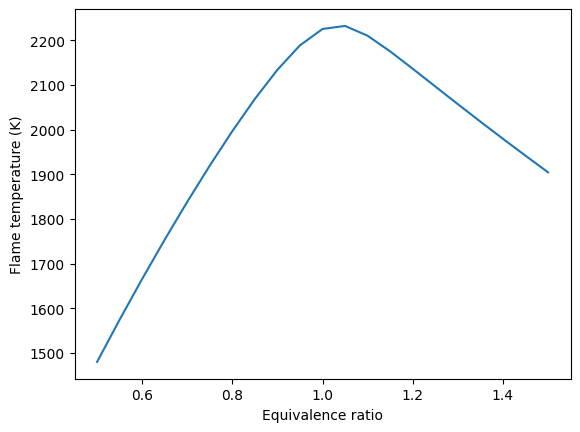

In [8]:

import numpy as np
import matplotlib.pyplot as plt

phis = np.linspace(0.5, 1.5, 21)
temps = []
for phi in phis:
    gas.TP = 300, ct.one_atm
    gas.set_equivalence_ratio(phi, 'CH4', 'O2:1, N2:3.76')
    gas.equilibrate('HP')
    temps.append(gas.T)

plt.plot(phis, temps)
plt.xlabel('Equivalence ratio')
plt.ylabel('Flame temperature (K)')
plt.show()

/tmp/ipykernel_6107/1955224889.py:2: DeprecationWarning: ReactorBase.__init__: After Cantera 3.2, the default value of the `clone` argument will be `True`, resulting in an independent copy of the `phase` being created for use by this reactor. Add the `clone=False` argument to retain the old behavior of sharing `Solution` objects.
  reactor = ct.IdealGasConstPressureReactor(gas)


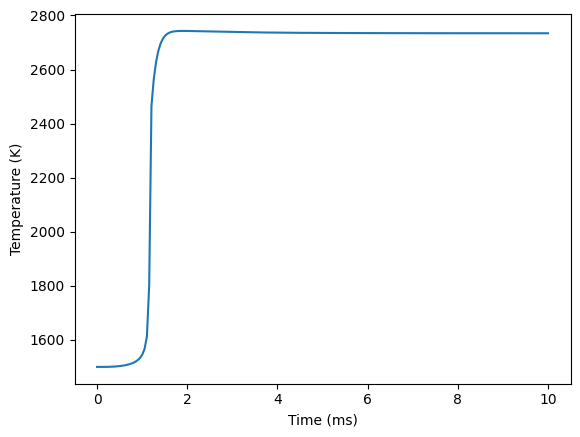

In [9]:

gas.TPX = 1500, ct.one_atm, 'CH4:1, O2:2, N2:7.52'
reactor = ct.IdealGasConstPressureReactor(gas)
sim = ct.ReactorNet([reactor])

times = np.linspace(0, 0.01, 200)
temps = []
for t in times:
    sim.advance(t)
    temps.append(reactor.T)

plt.plot(times * 1000, temps)
plt.xlabel('Time (ms)')
plt.ylabel('Temperature (K)')
plt.show()

/tmp/ipykernel_6107/212071324.py:2: DeprecationWarning: ReactorBase.__init__: After Cantera 3.2, the default value of the `clone` argument will be `True`, resulting in an independent copy of the `phase` being created for use by this reactor. Add the `clone=False` argument to retain the old behavior of sharing `Solution` objects.
  reactor = ct.IdealGasConstPressureReactor(gas)
/tmp/ipykernel_6107/212071324.py:10: DeprecationWarning: ReactorBase.thermo: To be removed after Cantera 3.2. Renamed to `phase`.
  data[name].append(reactor.thermo[name].X[0])


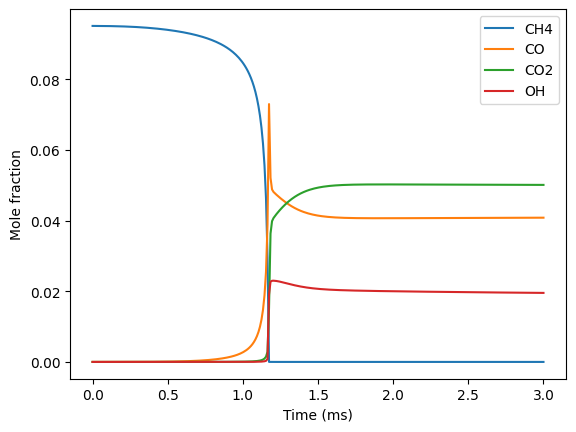

In [10]:

gas.TPX = 1500, ct.one_atm, 'CH4:1, O2:2, N2:7.52'
reactor = ct.IdealGasConstPressureReactor(gas)
sim = ct.ReactorNet([reactor])

times = np.linspace(0, 0.003, 300)
data = {'CH4': [], 'CO': [], 'CO2': [], 'OH': []}
for t in times:
    sim.advance(t)
    for name in data:
        data[name].append(reactor.thermo[name].X[0])

for name in data:
    plt.plot(times * 1000, data[name], label=name)
plt.xlabel('Time (ms)')
plt.ylabel('Mole fraction')
plt.legend()
plt.show()

/tmp/ipykernel_6107/1190095701.py:3: DeprecationWarning: ReactorBase.__init__: After Cantera 3.2, the default value of the `clone` argument will be `True`, resulting in an independent copy of the `phase` being created for use by this reactor. Add the `clone=False` argument to retain the old behavior of sharing `Solution` objects.
  r = ct.IdealGasConstPressureReactor(gas)


[45.446522212905805, 11.650678467377421, 3.4248841001693067, 1.1630564971852997, 0.4619000468428865]


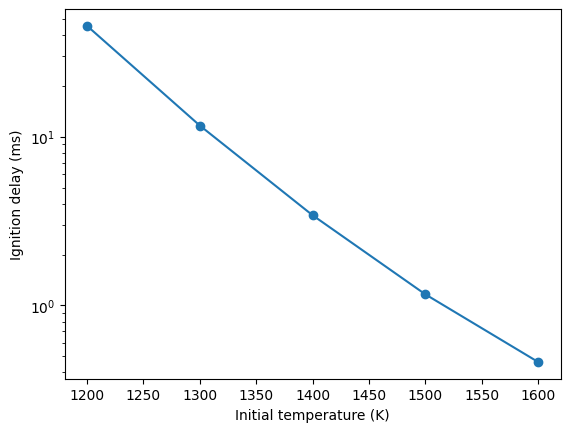

In [11]:

def delay(T0):
    gas.TPX = T0, ct.one_atm, 'CH4:1, O2:2, N2:7.52'
    r = ct.IdealGasConstPressureReactor(gas)
    sim = ct.ReactorNet([r])
    while r.T < T0 + 400 and sim.time < 1:
        sim.step()
    return sim.time * 1000

Ts = [1200, 1300, 1400, 1500, 1600]
delays = [delay(T) for T in Ts]
print(delays)

plt.semilogy(Ts, delays, 'o-')
plt.xlabel('Initial temperature (K)')
plt.ylabel('Ignition delay (ms)')
plt.show()

Activation energy (kJ/mol): 183.69214538772064


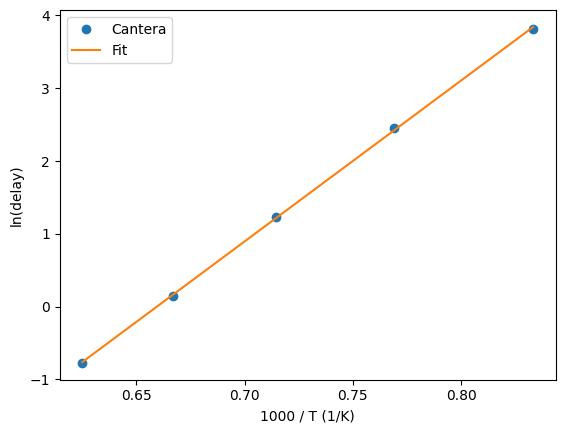

In [12]:

x = 1000 / np.array(Ts)
y = np.log(delays)
slope, intercept = np.polyfit(x, y, 1)
print('Activation energy (kJ/mol):', slope * 8.314)

plt.plot(x, y, 'o', label='Cantera')
plt.plot(x, slope * x + intercept, '-', label='Fit')
plt.xlabel('1000 / T (1/K)')
plt.ylabel('ln(delay)')
plt.legend()
plt.show()

/tmp/ipykernel_6107/3839624209.py:3: DeprecationWarning: ReactorBase.__init__: After Cantera 3.2, the default value of the `clone` argument will be `True`, resulting in an independent copy of the `phase` being created for use by this reactor. Add the `clone=False` argument to retain the old behavior of sharing `Solution` objects.
  r = ct.IdealGasConstPressureReactor(gas)


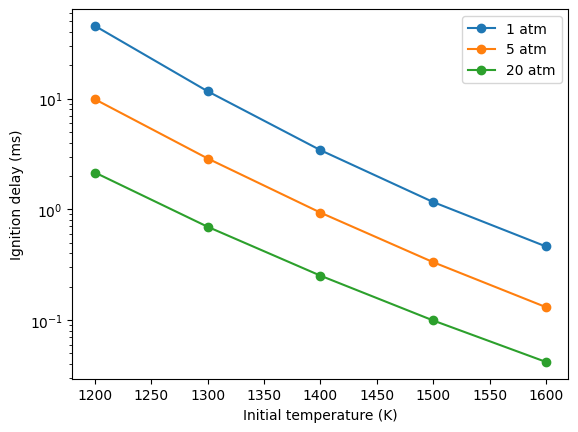

In [13]:

def delay_P(T0, P_atm):
    gas.TPX = T0, P_atm * ct.one_atm, 'CH4:1, O2:2, N2:7.52'
    r = ct.IdealGasConstPressureReactor(gas)
    sim = ct.ReactorNet([r])
    while r.T < T0 + 400 and sim.time < 1:
        sim.step()
    return sim.time * 1000

for P in [1, 5, 20]:
    d = [delay_P(T, P) for T in Ts]
    plt.semilogy(Ts, d, 'o-', label=f'{P} atm')

plt.xlabel('Initial temperature (K)')
plt.ylabel('Ignition delay (ms)')
plt.legend()
plt.show()